# compositional generalization

Scientific companion to [experiment.md](experiment.md), extending the workflow in
[modular_networks.ipynb](modular_networks.ipynb). The frozen six-module study tests
whether sparse distance-dependent shortcuts preserve specialization and improve
held-out composition by **at least 5 percentage points over both local and uniform
controls**. The baseline passes; that joint advantage is falsified within the tested
grid. Smaller effects and other regimes remain unresolved.

All executable cells below read tracked artifacts or perform reporting checks;
none train a model. Run from the checkout root using the project environment.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Arc
from matplotlib_inline.backend_inline import set_matplotlib_formats

from dynspec.composition import baseline_gate, read_rows
from dynspec.composition_plot import plot_summary

set_matplotlib_formats("svg")
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
root = Path.cwd()
baseline_config = json.loads((root / "module_baseline_config.json").read_text())
final_config = json.loads((root / "module_final_config.json").read_text())
baseline_summary = json.loads((root / "module_baseline_summary.json").read_text())
final_summary = json.loads((root / "module_final_summary.json").read_text())
baseline_rows = read_rows(root / "module_baseline_runs.csv")
final_rows = read_rows(root / "module_final_runs.csv")
baseline = pd.DataFrame(baseline_rows)
runs = pd.DataFrame(final_rows)
protocol = final_config["protocol"]
rules = {"local": "strongly local", "uniform": "uniform", "exponential": "exponential", "power": "power law"}
colors = {"local": "#424242", "uniform": "#7a6995", "exponential": "#cf771b", "power": "#20857b"}
print(f"frozen revision: {final_config['revision']}\nraw panel: {len(baseline)} baseline, {len(runs)} final runs")

frozen revision: 1bc6af3b9d020403d753d8d3cb341545e20fbd76
raw panel: 16 baseline, 2592 final runs


## architecture and module wiring

Six modules lie at positions 0–5. Only module 0 receives noisy symbolic digit A,
only module 5 receives B, and only module 3 has a task readout. Each module has
24 recurrent units and sends four hard binary bits per outgoing edge, for six
synchronous steps. The target is A when A+B is odd, otherwise B. No digit probe
loss or global readout bypass participates in training.

Every connected condition includes the bidirectional adjacent-module backbone.
Shortcut priors for distance d ≥ 2 are: local, .5 at d=2 and zero beyond;
uniform, .35; exponential, .6 exp[−.75(d−2)]; power law, .6(d/2)^−1.5.
Graphs are sampled conditional on an exact edge or cable budget, so these priors
are **not** the realized marginal probabilities.

Below are actual seed-0, 14-directed-edge graphs from the tracked final panel.
Each line/arc represents two directed edges. Grey segments are the common
backbone; colored arcs are shortcuts. Module coordinates determine cable length,
not neuron distances or transmission delays. These are examples, not average graphs.

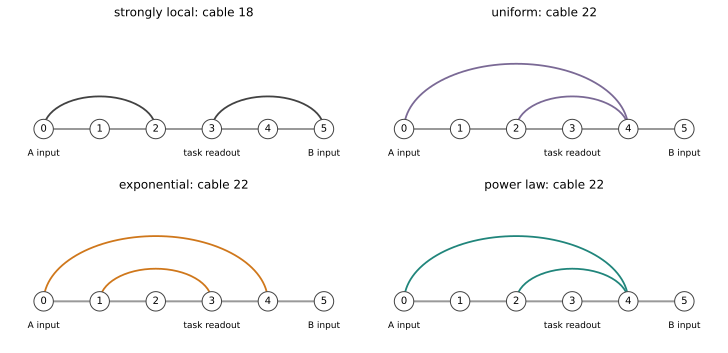

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(10, 4.8), layout="constrained")
for ax, (rule, label) in zip(axes.flat, rules.items()):
    row = runs.query("view == 'edges' and budget == 14 and seed == 0 and split == 0 and condition == @rule").iloc[0]
    graph = np.array(list(row.graph), dtype=int).reshape(6, 6)
    for i, j in zip(*np.where(np.triu(graph, 1))):
        if j - i == 1:
            ax.plot([i, j], [0, 0], color="#999999", lw=2, zorder=1)
        else:
            ax.add_patch(Arc(((i + j) / 2, 0), j - i, .55 * (j - i), theta1=0, theta2=180, color=colors[rule], lw=1.8))
    ax.scatter(range(6), [0] * 6, s=380, facecolor="white", edgecolor="#424242", zorder=3)
    for i in range(6):
        ax.text(i, 0, str(i), ha="center", va="center", zorder=4)
    for i, text in [(0, "A input"), (3, "task readout"), (5, "B input")]:
        ax.text(i, -.45, text, ha="center", fontsize=9)
    ax.set(title=f"{label}: cable {row.cable_cost:g}", xlim=(-.65, 5.65), ylim=(-.75, 1.8))
    ax.axis("off")
display(fig)
plt.close(fig)

## baseline gate and validity

Recompute the complete-graph gate from the eight raw reference seeds, using the
frozen engine's reporting function. The eight chain runs are diagnostics and do
not determine this gate. Values below are fractions, except normalized source
specialization and the seed count. A passing gate establishes cooperation and
specialization in this reduced architecture, not replication of the perceptual study.

In [3]:
gate = baseline_gate(baseline_rows)
assert gate["passed"] and gate["checks"] == baseline_summary["baseline_gate"]["checks"]
for key, value in gate["means"].items():
    np.testing.assert_allclose(value, baseline_summary["baseline_gate"]["means"][key], atol=1e-12, rtol=0)
dense = baseline.query("condition == 'dense'")
consistent_seeds = ((dense.seen >= .90) & (dense.specialization >= .10)).sum()
thresholds = protocol["baseline_gate"]
gate_table = pd.DataFrame([
    ("task accuracy", gate["means"]["seen"], thresholds["seen"]),
    ("A-selected accuracy", gate["means"]["seen_a"], thresholds["branch"]),
    ("B-selected accuracy", gate["means"]["seen_b"], thresholds["branch"]),
    ("source specialization", gate["means"]["specialization"], thresholds["specialization"]),
    ("own-digit probe", gate["means"]["own_probe"], thresholds["own_probe"]),
    ("all-cut accuracy drop", gate["means"]["cooperation_drop"], thresholds["cooperation_drop"]),
    ("consistent seeds (of 8)", consistent_seeds, 6),
], columns=["metric", "observed", "minimum"])
gate_table["passed"] = gate_table.observed >= gate_table.minimum
assert gate_table.passed.all()
display(gate_table.round(5))

,metric,observed,minimum,passed
0,task accuracy,0.99980,0.95,True
1,A-selected accuracy,0.99965,0.95,True
2,B-selected accuracy,0.99995,0.95,True
3,source specialization,0.34389,0.10,True
4,own-digit probe,0.96071,0.90,True
5,all-cut accuracy drop,0.89971,0.20,True
6,consistent seeds (of 8),8.00000,6.00,True


In [4]:
assert baseline_config["revision"] == final_config["revision"]
assert baseline_config["protocol_hash"] == final_config["protocol_hash"]
assert baseline_config["protocol"] == protocol
assert final_summary["baseline_gate"] == baseline_summary["baseline_gate"]
for config in (baseline_config, final_config):
    for name in ("dynspec/composition.py", "test_composition.py"):
        assert hashlib.sha256((root / name).read_bytes()).hexdigest() == config["hashes"][name]
# experiment.md is a living report; its preregistered hash refers to the frozen revision.
expected = {(s, k, r, v, b) for s in protocol["seeds"] for k in range(3)
            for v, b in protocol["cells"] for r in rules}
expected |= {(s, k, r, "diagnostic", 0) for s in protocol["seeds"] for k in range(3)
             for r in ("chain", "disconnected")}
keys = list(runs[["seed", "split", "condition", "view", "budget"]].itertuples(index=False, name=None))
assert len(keys) == len(set(keys)) and set(keys) == expected
held_sets = []
for split in final_config["splits"]:
    train, held = (set(map(tuple, split[key])) for key in ("train", "test"))
    assert len(train) == 80 and len(held) == 20 and not train & held
    for pairs in (train, held):
        pairs = np.array(sorted(pairs))
        a, b = pairs.T
        selects_a = (a + b) % 2 == 1
        labels = np.where(selects_a, a, b)
        assert selects_a.sum() == len(pairs) // 2
        for values in (a, b, labels):
            assert np.all(np.bincount(values, minlength=10) == len(pairs) // 10)
        for branch in (selects_a, ~selects_a):
            assert np.all(np.bincount(labels[branch], minlength=10) == len(pairs) // 20)
    held_sets.append(held)
assert all(not held_sets[i] & held_sets[j] for i in range(3) for j in range(i))
primary = runs[runs.view != "diagnostic"]
assert np.allclose(runs.query("condition == 'disconnected'").held, .10)
assert np.allclose(runs.ablated, .10)
assert np.allclose(runs.cooperation_drop, runs.held - runs.ablated)
source_drops = primary.groupby(["view", "budget", "condition"])[["cut_a_drop", "cut_b_drop"]].mean()
assert (source_drops > 0).all().all()
assert (primary.query("view == 'edges'").edges == primary.query("view == 'edges'").budget).all()
assert (primary.query("view == 'cost'").cable_cost == primary.query("view == 'cost'").budget).all()
print("source hashes, complete final panel, balanced splits, exact budgets, 10% cut/disconnected outputs, and both-source reliance verified")

source hashes, complete final panel, balanced splits, exact budgets, 10% cut/disconnected outputs, and both-source reliance verified


## matched-edge and matched-cost results

Average the three overlapping train/test splits **within each seed** before
averaging 48 independent seeds. Matched edges hold active connection capacity
fixed and allow cable cost to vary; matched cost holds cable fixed and allows
edge count/capacity to vary. Cable is summed directed module distance; four
binary channels multiply it by four. Neither view matches both quantities.

The table reproduces the complete main panel in experiment.md, including the two
unmatched diagnostics. Source specialization is the normalized own-minus-other
linear probe score, not a claim about every module's cognitive role.

In [5]:
metrics = ["seen", "held", "specialization", "cooperation_drop", "cable_cost", "edges"]
seed_means = runs.groupby(["view", "budget", "condition", "seed"])[metrics].mean()
means = seed_means.groupby(level=["view", "budget", "condition"]).mean()
order = [(v, b, r) for v, b in protocol["cells"] for r in rules]
order += [("diagnostic", 0, r) for r in ("chain", "disconnected")]
means = means.loc[order]
for (view, budget, rule), row in means.iterrows():
    stored = final_summary["means"][f"{view}:{budget}:{rule}"]
    np.testing.assert_allclose(row, [stored[m] for m in metrics], atol=1e-12, rtol=0)
table = means.copy()
table[["seen", "held", "cooperation_drop"]] *= 100
table.columns = ["seen (%)", "held (%)", "specialization", "all-cut drop (pp)", "cable cost", "directed edges"]
display(table.round(3))

seen (%)  held (%)  specialization  \
view       budget condition                                          
edges      14     local           97.640    61.417           0.852   
                  uniform         99.257    62.338           0.629   
                  exponential     98.141    62.062           0.759   
                  power           98.836    62.076           0.767   
           18     local           99.985    66.430           0.730   
                  uniform         99.945    67.993           0.460   
                  exponential     99.979    65.415           0.663   
                  power           99.973    67.242           0.602   
cost       22     local           99.992    66.355           0.785   
                  uniform         99.471    61.049           0.657   
                  exponential     99.871    64.786           0.765   
                  power           99.845    63.937           0.748   
           26     local           99.985    66.430           0.730   
                  uniform         99.697    67.154           0.593   
                  exponential     99.785    64.378           0.681   
                  power           99.767    65.771           0.637   
diagnostic 0      chain           97.272    55.214           0.992   
                  disconnected    10.000    10.000           1.000   

                                all-cut drop (pp)  cable cost  directed edges  
view       budget condition                                                    
edges      14     local                    51.417      18.000          14.000  
                  uniform                  52.338      22.333          14.000  
                  exponential              52.062      19.667          14.000  
                  power                    52.076      19.792          14.000  
           18     local                    56.430      26.000          18.000  
                  uniform                  57.993      33.875          18.000  
                  exponential              55.415      28.792          18.000  
                  power                    57.242      29.875          18.000  
cost       22     local                    56.355      22.000          16.000  
                  uniform                  51.049      22.000          14.167  
                  exponential              54.786      22.000          15.750  
                  power                    53.937      22.000          15.583  
           26     local                    56.430      26.000          18.000  
                  uniform                  57.154      26.000          15.583  
                  exponential              54.378      26.000          17.083  
                  power                    55.771      26.000          16.750  
diagnostic 0      chain                    45.214      10.000          10.000  
                  disconnected              0.000       0.000           0.000

### performance versus wiring

Recreate the existing Pareto comparison from the stored summary using the
reporting-only helper. Intervals are nominal 95% seed intervals. Segments connect
only the two frozen budgets; the empirical frontier is descriptive, not an
uncertainty-certified dominance claim. Every candidate remains below the 80%
held-out support criterion.

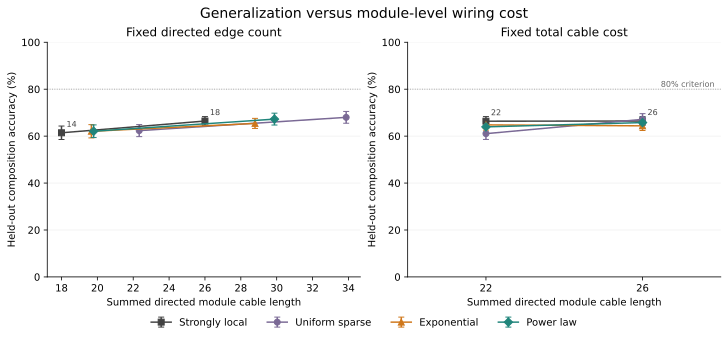

In [6]:
fig = plot_summary(final_summary)
display(fig)
plt.close(fig)

## frozen decision

Each of eight candidates must gain ≥5 pp over **both** matched controls. For every
candidate, at least one learned control has an upper simultaneous bound below
+5 pp. These Bonferroni intervals have 95% family coverage across 16 planned
contrasts; the df is 47. This falsifies that threshold-specific claim in this grid,
not all smaller gains or the broader hypothesis. Some bounds are close to +5 pp.
Failure to reach 80% held accuracy alone is not the falsification argument.

In [7]:
comparisons = pd.DataFrame(final_summary["comparisons"])
contrast_rows = []
for candidate in final_summary["candidates"]:
    name = candidate["candidate"]
    panel = comparisons[comparisons.candidate == name]
    assert len(panel) == 2 and panel.valid_learning.all()
    assert any(bounds[1] < protocol["minimum_gain"] for bounds in panel.family_ci95)
    assert candidate["advantage_refuted"]
    row = {"candidate": name}
    for contrast in panel.itertuples():
        view, budget, rule = contrast.candidate.split(":")
        control = contrast.control.split(":")[-1]
        delta = (seed_means.loc[(view, int(budget), rule), "held"]
                 - seed_means.loc[(view, int(budget), control), "held"])
        np.testing.assert_allclose(delta, contrast.seed_differences, atol=1e-12, rtol=0)
        np.testing.assert_allclose(delta.mean(), contrast.difference, atol=1e-12, rtol=0)
        lo, hi = np.array(contrast.family_ci95) * 100
        row[f"vs {control} (pp; family CI)"] = f"{100 * contrast.difference:+.3f} [{lo:+.3f}, {hi:+.3f}]"
    contrast_rows.append(row)
assert final_summary["decision"] == "falsified in this tested grid"
display(pd.DataFrame(contrast_rows).set_index("candidate"))
print(final_summary["decision"])
print(f"nominal ±2.5 pp precision target met: {comparisons.target_precision_met.sum()}/16 contrasts")

,vs local (pp; family CI),vs uniform (pp; family CI)
candidate,,
edges:14:exponential,"+0.645 [-3.367, +4.658]","-0.276 [-5.663, +5.111]"
edges:14:power,"+0.659 [-4.042, +5.360]","-0.262 [-5.489, +4.966]"
edges:18:exponential,"-1.015 [-4.615, +2.585]","-2.578 [-7.173, +2.017]"
edges:18:power,"+0.812 [-3.279, +4.902]","-0.751 [-5.853, +4.351]"
cost:22:exponential,"-1.569 [-4.185, +1.047]","+3.737 [-0.787, +8.262]"
cost:22:power,"-2.418 [-5.194, +0.357]","+2.888 [-1.704, +7.480]"
cost:26:exponential,"-2.052 [-5.163, +1.058]","-2.776 [-7.212, +1.660]"
cost:26:power,"-0.659 [-4.728, +3.411]","-1.383 [-5.120, +2.355]"


falsified in this tested grid
nominal ±2.5 pp precision target met: 5/16 contrasts


## exploratory specialization and wiring observation

At fixed edge count, distance-biased rules retain stronger source specialization
and use less cable than uniform, with held-out means often nearby. This is a
useful descriptive observation, not proof of performance equivalence or of a
corrected-family advantage. The table gives differences against uniform; compare
these with the paired performance intervals above. At exact cost, local at 22 and
uniform at 26 have the highest mean held-out performance.

In [8]:
tradeoff = []
for budget in (14, 18):
    uniform = means.loc[("edges", budget, "uniform")]
    for rule in ("exponential", "power"):
        point = means.loc[("edges", budget, rule)]
        tradeoff.append({
            "edges": budget, "rule": rules[rule],
            "less cable vs uniform (%)": 100 * (1 - point.cable_cost / uniform.cable_cost),
            "specialization difference": point.specialization - uniform.specialization,
            "held difference (pp)": 100 * (point.held - uniform.held),
        })
display(pd.DataFrame(tradeoff).set_index(["edges", "rule"]).round(3))

less cable vs uniform (%)  specialization difference  \
edges rule                                                                
14    exponential                     11.940                      0.130   
      power law                       11.381                      0.139   
18    exponential                     15.006                      0.203   
      power law                       11.808                      0.142   

                   held difference (pp)  
edges rule                               
14    exponential                -0.276  
      power law                  -0.262  
18    exponential                -2.578  
      power law                  -0.751

## limits and reproduction

Module 3 is nearer source B than source A. Held-out A-selected accuracy is lower
than B-selected accuracy despite balanced splits; output placement and task
asymmetries were not counterbalanced. The cause remains unresolved. The forced
backbone, four-bit bandwidth, six-step dynamics, sparse parameter grid, and missed
precision targets limit interpretation. This symbolic/reduced experiment is
**not a full replication of Béna & Goodman**: no MNIST/EMNIST perception, original
specialization sweeps, or winner-take-all architecture is reproduced.

`dynspec/composition.py` is the deterministic batch engine. To reproduce the
frozen experiment, use a separate checkout at the exact revision recorded in both
configs (below); use fresh prefixes to preserve the tracked results. Commands
are intentionally text, not notebook cells. Numerical identity across machines
or library versions is not guaranteed.

```sh
git worktree add --detach ../specialization-frozen 1bc6af3b9d020403d753d8d3cb341545e20fbd76
cd ../specialization-frozen
uv sync --locked
uv run --locked python -m unittest -v test_composition
uv run --locked python -m dynspec.composition --stage baseline --output reproduced_baseline --workers 4
uv run --locked python -m dynspec.composition --stage final --baseline reproduced_baseline --output reproduced_final --workers 8
```

The tracked figure's reporting helper was added after the frozen run. From this
current checkout it can also render a fresh figure without training:

```sh
uv run --locked python -m dynspec.composition_plot module_final_summary.json --output reproduced_pareto.svg
```

The invalid pilot files are absent from the current tree and preserved at
`5bdc38d`, with execution source at `7cc1986` and preregistration at `51a2315`.
For example, `git show 5bdc38d:composition_runs.csv` retrieves the historical raw
panel. See experiment.md for the retained pilot report and full protocol.